In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Load CSV File
df = pd.read_csv("House Prediction.csv")
display(df.head())


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


# Data Understanding

In [7]:
#Data Understanding
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

(4600, 18)
<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float

# EDA

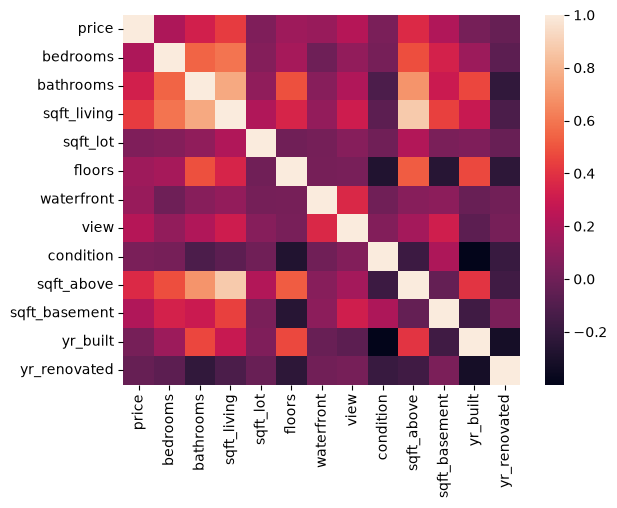

In [8]:
plt.Figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True))
plt.show()

<Axes: xlabel='sqft_above', ylabel='price'>

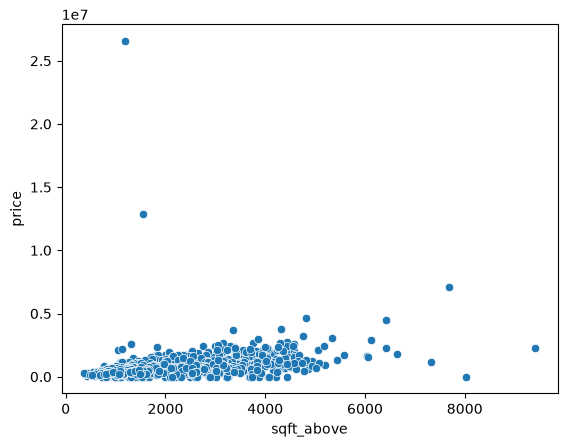

In [10]:
sns.scatterplot(x='sqft_above',y='price', data=df)

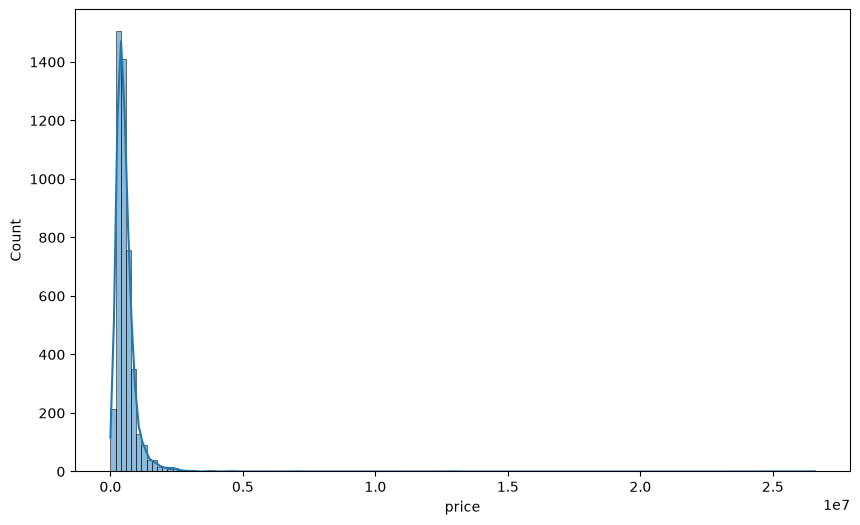

In [20]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], kde=True)
plt.show()

Text(0.5, 0, 'log_price')

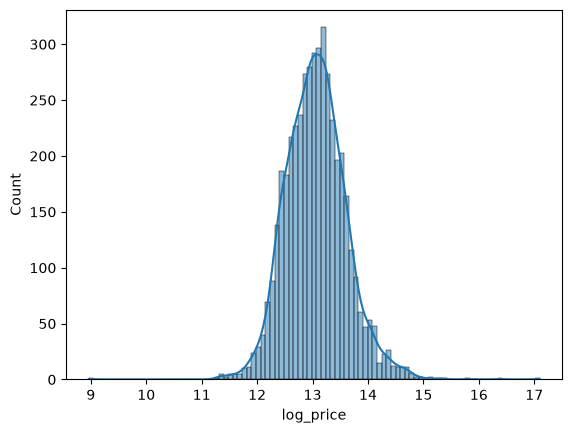

In [26]:
df = df[df['price']>0]
sns.histplot(np.log1p(df['price']), kde=True)
plt.xlabel('log_price')

In [29]:
#Outliers
num_features = df.select_dtypes(include='number') #int64 or float 64
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((num_features < lower_bound) | (num_features > upper_bound))
print(outliers.sum())

price              240
bedrooms           115
bathrooms          130
sqft_living        128
sqft_lot           540
floors               0
waterfront          30
view               448
condition            6
sqft_above         111
sqft_basement       83
yr_built             0
yr_renovated         0
log_price           78
log_sqft_living     26
log_sqft_lot       516
dtype: int64
